In [1]:
import importlib
import importlib.metadata as importlib_metadata
import subprocess
import sys


def installed_version(dist_name):
    try:
        return importlib_metadata.version(dist_name)
    except importlib_metadata.PackageNotFoundError:
        return None


def pip_install_no_deps(spec):
    cmd = [sys.executable, "-m", "pip", "install", "-q", "--no-deps", spec]
    print("Running:", " ".join(cmd))
    subprocess.check_call(cmd)


TORCH_VERSION_BEFORE = installed_version("torch")
TORCHVISION_VERSION_BEFORE = installed_version("torchvision")
if TORCH_VERSION_BEFORE is None or TORCHVISION_VERSION_BEFORE is None:
    raise RuntimeError("torch and torchvision must be preinstalled (Colab runtime). "
                       "This notebook never installs or upgrades them.")

if installed_version("scipy") is None:
    pip_install_no_deps("scipy")
if installed_version("tqdm") is None:
    pip_install_no_deps("tqdm")
if installed_version("pytorch-fid") != "0.3.0":
    pip_install_no_deps("pytorch-fid==0.3.0")
importlib.invalidate_caches()

assert installed_version("pytorch-fid") == "0.3.0", "pytorch-fid==0.3.0 is required"
assert installed_version("torch") == TORCH_VERSION_BEFORE, "torch version changed - this must never happen"
assert installed_version("torchvision") == TORCHVISION_VERSION_BEFORE, "torchvision version changed"
print("torch", TORCH_VERSION_BEFORE, "| torchvision", TORCHVISION_VERSION_BEFORE,
      "| scipy", installed_version("scipy"), "| tqdm", installed_version("tqdm"),
      "| pytorch-fid", installed_version("pytorch-fid"))

Running: /usr/bin/python3 -m pip install -q --no-deps pytorch-fid==0.3.0
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | scipy 1.16.3 | tqdm 4.67.3 | pytorch-fid 0.3.0


In [2]:
import csv
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"


def describe_hardware():
    info = {
        "device_type": DEVICE.type,
        "cpu": platform.processor() or platform.machine(),
        "cpu_count": os.cpu_count(),
        "platform": platform.platform(),
    }
    if USE_CUDA:
        props = torch.cuda.get_device_properties(0)
        info["gpu_name"] = torch.cuda.get_device_name(0)
        info["gpu_total_memory_gb"] = round(props.total_memory / 1024 ** 3, 2)
        info["gpu_count"] = torch.cuda.device_count()
    else:
        info["gpu_name"] = None
    return info


HARDWARE = describe_hardware()
RUNTIME_VERSIONS = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "pytorch_fid": installed_version("pytorch-fid"),
    "tqdm": installed_version("tqdm"),
    "cuda_runtime": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if USE_CUDA else None,
}
print("Device:", DEVICE)
print(json.dumps(HARDWARE, indent=2))
print(json.dumps(RUNTIME_VERSIONS, indent=2))

Device: cuda
{
  "device_type": "cuda",
  "cpu": "x86_64",
  "cpu_count": 2,
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "gpu_name": "Tesla T4",
  "gpu_total_memory_gb": 14.56,
  "gpu_count": 1
}
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0",
  "pytorch_fid": "0.3.0",
  "tqdm": "4.67.3",
  "cuda_runtime": "13.0",
  "cudnn": 92800
}


In [3]:
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

MODEL_ID = "03"
MODEL_NAME = "Vanilla GAN (fully connected)"
NOTEBOOK_NAME = "03_vanilla_gan_claude.ipynb"

NUM_CLASSES = 10
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
IMAGE_SHAPE = (1, 28, 28)
IMAGE_NUMEL = 784
TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 5600, 700, 700
EXPECTED_TOTALS = {"train": 56000, "validation": 7000, "test": 7000}
TOTAL_POOLED = 70000

LATENT_DIM = 100
BATCH_SIZE = 128
NUM_EPOCHS = 30
LR_G = 2e-4
LR_D = 2e-4
ADAM_BETAS = (0.5, 0.999)
ADAM_EPS = 1e-8
WEIGHT_DECAY = 0.0
INIT_STD = 0.02
LEAKY_SLOPE = 0.2
REAL_LABEL = 1.0
FAKE_LABEL = 0.0
NUM_WORKERS = 2
PIN_MEMORY = USE_CUDA

EXPECTED_G_PARAMS = 559_632
EXPECTED_D_PARAMS = 533_505

NUM_MONITOR_SAMPLES = 64
PROGRESSION_EPOCHS = [1, 5, 10, 15, 20, 25, 30]
NUM_PROGRESSION_SHOWN = 16

VAL_FID_EVERY = 5
VAL_FID_EPOCHS = list(range(VAL_FID_EVERY, NUM_EPOCHS + 1, VAL_FID_EVERY))
VAL_FID_NUM_REAL = 3000
VAL_FID_NUM_FAKE = 3000
TEST_FID_NUM_REAL = 7000
TEST_FID_NUM_FAKE = 7000
FID_FEATURE_DIM = 2048
FID_BATCH_SIZE = 64
GEN_BATCH_SIZE = 500

NUM_RANDOM_SAMPLES = 16
INTERP_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
INTERP_CLASS_A, INTERP_CLASS_B = 0, 1
INVERSION_RESTARTS = 4
INVERSION_STEPS = 400
INVERSION_LR = 0.05
INVERSION_Z_PRIOR_WEIGHT = 1e-4

LATENCY_BATCH_SIZE = 64
LATENCY_WARMUP_RUNS = 20
LATENCY_TIMED_RUNS = 100

DATALOADER_SHUFFLE_SEED = 42
TRAIN_NOISE_SEED = 42
MONITOR_NOISE_SEED = 1001
VAL_FID_NOISE_SEED = 1002
TEST_FID_NOISE_SEED = 1003
RANDOM_SAMPLES_SEED = 1004
INVERSION_SEEDS = {"class_A": 1005, "class_B": 1006}
LATENCY_NOISE_SEED = 1007
SANITY_CHECK_SEED = 1008


def seeded_normal(n, dim, seed):
    gen = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randn(n, dim, generator=gen)


def cuda_sync():
    if USE_CUDA:
        torch.cuda.synchronize()

In [4]:
try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError("This notebook must run in Google Colab (google.colab not found).") from exc

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.is_dir():
    raise RuntimeError(f"Google Drive is not mounted at {DRIVE_ROOT}")

PROJECT_DIR = DRIVE_ROOT / "generative-model-comparison" / "03_vanilla_gan"
DATA_DIR = PROJECT_DIR / "data" / "fashion_mnist"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = RESULTS_DIR / "best_model.pth"
LAST_CKPT_PATH = RESULTS_DIR / "last_checkpoint.pth"
METRICS_PATH = RESULTS_DIR / "metrics.json"
HISTORY_CSV_PATH = RESULTS_DIR / "training_history.csv"
CONFIG_PATH = RESULTS_DIR / "experiment_config.json"
SPLIT_REPORT_PATH = RESULTS_DIR / "split_report.json"
FIG_PATHS = {
    "training_curves": FIG_DIR / "training_curves.png",
    "random_samples_4x4": FIG_DIR / "random_samples_4x4.png",
    "training_sample_progression": FIG_DIR / "training_sample_progression.png",
    "latent_interpolation": FIG_DIR / "latent_interpolation.png",
    "latent_inversion_endpoints": FIG_DIR / "latent_inversion_endpoints.png",
}
REQUIRED_OUTPUTS = [BEST_MODEL_PATH, LAST_CKPT_PATH, METRICS_PATH, HISTORY_CSV_PATH,
                    CONFIG_PATH, SPLIT_REPORT_PATH] + list(FIG_PATHS.values())

def to_jsonable(obj):
    """Convert to plain JSON types. Non-finite floats become None (null); never NaN/Infinity."""
    if obj is None or isinstance(obj, bool):
        return obj
    if isinstance(obj, str):
        return str(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        value = float(obj)
        return value if math.isfinite(value) else None
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, torch.Tensor):
        return to_jsonable(obj.detach().cpu().tolist())
    if isinstance(obj, Path):
        return str(obj)
    raise TypeError(f"Cannot serialise object of type {type(obj)}")


def write_json_strict(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(to_jsonable(obj), f, indent=2, allow_nan=False)
    os.replace(tmp, path)


def load_json_strict(path):
    def _reject(constant):
        raise ValueError(f"Non-finite JSON constant {constant!r} found in {path}")
    with open(path) as f:
        return json.load(f, parse_constant=_reject)


def save_torch_atomic(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def save_figure(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    assert Path(path).is_file() and Path(path).stat().st_size > 0, f"Figure not written: {path}"
    print("Saved figure:", path)

EXPERIMENT_CONFIG = {
    "model_id": MODEL_ID,
    "model_name": MODEL_NAME,
    "notebook": NOTEBOOK_NAME,
    "seed": SEED,
    "dataset": {
        "name": "Fashion-MNIST",
        "source": "torchvision.datasets.FashionMNIST train=True (60000) then train=False (10000), pooled in that order",
        "transform": "transforms.ToTensor() only",
        "canonical_image_shape": list(IMAGE_SHAPE),
        "canonical_value_range": [0.0, 1.0],
        "gan_training_input_range": [-1.0, 1.0],
        "gan_input_conversion": "x * 2 - 1 applied to real training batches",
        "generated_output_conversion": "(x + 1) / 2 for display and FID",
        "augmentation": None,
        "class_names": CLASS_NAMES,
    },
    "split": {
        "method": "class-stratified 80/10/10 with numpy default_rng(42); per class ascending: shuffle, [:5600] train, "
                  "[5600:6300] validation, [6300:] test; concatenate as int64; final shuffle train, validation, test",
        "seed": SEED,
        "per_class": {"train": TRAIN_PER_CLASS, "validation": VAL_PER_CLASS, "test": TEST_PER_CLASS},
        "totals": EXPECTED_TOTALS,
    },
    "dataloaders": {
        "batch_size": BATCH_SIZE, "train_shuffle": True, "validation_shuffle": False, "test_shuffle": False,
        "train_shuffle_generator_seed": DATALOADER_SHUFFLE_SEED, "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY, "drop_last": False,
    },
    "architecture": {
        "latent_dim": LATENT_DIM,
        "latent_prior": "N(0, I)",
        "generator": ["Linear(100,256)", "ReLU", "Linear(256,512)", "ReLU", "Linear(512,784)", "Tanh",
                      "Reshape [B,1,28,28]"],
        "discriminator": ["Flatten(784)", "Linear(784,512)", "LeakyReLU(0.2)", "Linear(512,256)",
                          "LeakyReLU(0.2)", "Linear(256,1)", "Sigmoid"],
        "weight_init": {"linear_weight": "normal(mean=0, std=0.02)", "linear_bias": "zeros"},
        "expected_trainable_parameters": {"generator": EXPECTED_G_PARAMS, "discriminator": EXPECTED_D_PARAMS},
    },
    "hyperparameters": {
        "loss": "nn.BCELoss", "real_label": REAL_LABEL, "fake_label": FAKE_LABEL,
        "discriminator_loss": "0.5 * (BCE(D(real), 1) + BCE(D(G(z).detach()), 0))",
        "generator_loss": "non-saturating BCE(D(G(z)), 1)",
        "updates_per_batch": "1 discriminator step, then 1 generator step",
        "generator_step_noise": "the same per-batch z / G(z) used in the discriminator step of that batch",
        "optimizer": "Adam (separate for G and D)",
        "lr_generator": LR_G, "lr_discriminator": LR_D, "adam_betas": list(ADAM_BETAS), "adam_eps": ADAM_EPS,
        "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE, "epochs": NUM_EPOCHS,
        "train_noise_generator": f"dedicated CPU torch.Generator seeded {TRAIN_NOISE_SEED}",
        "discriminator_frozen_during_generator_step": True,
        "not_used": ["early stopping", "LR scheduler", "gradient clipping", "mixed precision",
                     "one-sided label smoothing", "label flipping", "gradient penalty",
                     "spectral normalization", "extra regularization"],
    },
    "monitoring": {
        "fixed_monitor_noise_count": NUM_MONITOR_SAMPLES, "fixed_monitor_noise_seed": MONITOR_NOISE_SEED,
        "diversity_indicators": {
            "fixed_noise_pixel_std": "mean over 784 pixels of the population std (correction=0) across the 64 images, [0,1] scale",
            "fixed_noise_mean_pairwise_l1": "mean over all 2016 image pairs of the per-pixel mean absolute difference, [0,1] scale",
        },
        "progression_epochs": PROGRESSION_EPOCHS, "progression_images_shown": NUM_PROGRESSION_SHOWN,
        "epoch_wall_time_definition": "training + fixed-noise monitoring + scheduled validation FID + best-checkpoint "
                                      "save; excludes the last-checkpoint write and CSV append that follow it",
    },
    "fid": {
        "implementation": "pytorch-fid==0.3.0",
        "network": "InceptionV3(use_fid_inception=True) FID weights, ImageNet-pretrained",
        "block": "pool3", "block_index": int(InceptionV3.BLOCK_INDEX_BY_DIM[FID_FEATURE_DIM]),
        "feature_dim": FID_FEATURE_DIM, "resize_input": True, "normalize_input": True,
        "grayscale_to_rgb": "repeat single channel 3 times", "input_range": [0.0, 1.0],
        "statistics_dtype": "float64", "distance_function": "pytorch_fid.fid_score.calculate_frechet_distance",
        "validation": {"epochs": VAL_FID_EPOCHS, "num_real": VAL_FID_NUM_REAL, "num_fake": VAL_FID_NUM_FAKE,
                       "real_source": "first 3000 images of the final shuffled validation split",
                       "fake_noise_seed": VAL_FID_NOISE_SEED, "purpose": "checkpoint selection only"},
        "test": {"num_real": TEST_FID_NUM_REAL, "num_fake": TEST_FID_NUM_FAKE,
                 "real_source": "all 7000 held-out stratified test images",
                 "fake_noise_seed": TEST_FID_NOISE_SEED, "checkpoint": "best_model.pth"},
        "inception_batch_size": FID_BATCH_SIZE,
    },
    "random_samples": {"count": NUM_RANDOM_SAMPLES, "grid": [4, 4], "noise_seed": RANDOM_SAMPLES_SEED},
    "latent_interpolation": {
        "alphas": INTERP_ALPHAS, "class_A": INTERP_CLASS_A, "class_B": INTERP_CLASS_B,
        "endpoint_selection": "first position in the final test split with the given class label",
        "endpoint_method": "latent inversion of a frozen best generator (no encoder exists)",
        "inversion_objective": "MSE((G(z)+1)/2, target) + 1e-4 * mean(z^2)",
        "restarts": INVERSION_RESTARTS, "steps_per_restart": INVERSION_STEPS, "optimizer": "Adam",
        "learning_rate": INVERSION_LR, "z_prior_weight": INVERSION_Z_PRIOR_WEIGHT,
        "restart_seeds": INVERSION_SEEDS, "restart_selection": "lowest final objective",
    },
    "latency": {"definition": "Generator forward pass only", "batch_size": LATENCY_BATCH_SIZE,
                "warmup_runs": LATENCY_WARMUP_RUNS, "timed_runs": LATENCY_TIMED_RUNS,
                "noise_seed": LATENCY_NOISE_SEED, "no_grad": True, "cuda_sync_each_run": True},
    "rng_seeds": {
        "dataloader_shuffle": DATALOADER_SHUFFLE_SEED, "train_noise": TRAIN_NOISE_SEED,
        "monitor_noise": MONITOR_NOISE_SEED, "val_fid_noise": VAL_FID_NOISE_SEED,
        "test_fid_noise": TEST_FID_NOISE_SEED, "random_samples": RANDOM_SAMPLES_SEED,
        "inversion": INVERSION_SEEDS, "latency_noise": LATENCY_NOISE_SEED, "sanity_checks": SANITY_CHECK_SEED,
        "model_init": "torch.manual_seed(42) immediately before building G then D",
    },
    "paths": {"project_dir": str(PROJECT_DIR), "data_dir": str(DATA_DIR), "results_dir": str(RESULTS_DIR)},
    "device": str(DEVICE),
    "hardware": HARDWARE,
    "runtime_versions": RUNTIME_VERSIONS,
}
write_json_strict(EXPERIMENT_CONFIG, CONFIG_PATH)
print("Project dir:", PROJECT_DIR)
print("Config written:", CONFIG_PATH)

Mounted at /content/drive
Project dir: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan
Config written: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/experiment_config.json


In [5]:
to_tensor = transforms.ToTensor()
fashion_train = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=True, transform=to_tensor)
fashion_test = datasets.FashionMNIST(root=str(DATA_DIR), train=False, download=True, transform=to_tensor)
assert len(fashion_train) == 60000 and len(fashion_test) == 10000


def cache_with_to_tensor(ds):
    images = torch.empty((len(ds), *IMAGE_SHAPE), dtype=torch.float32)
    for i in range(len(ds)):
        img, _ = ds[i]
        images[i] = img
    return images


t0 = time.perf_counter()
train_images = cache_with_to_tensor(fashion_train)
test_images = cache_with_to_tensor(fashion_test)
assert torch.equal(train_images, fashion_train.data.unsqueeze(1).float().div(255.0))
assert torch.equal(test_images, fashion_test.data.unsqueeze(1).float().div(255.0))
ALL_IMAGES = torch.cat([train_images, test_images], dim=0).contiguous()
del train_images, test_images

labels = np.concatenate([fashion_train.targets.numpy().astype(np.int64),
                         fashion_test.targets.numpy().astype(np.int64)])
ALL_LABELS = torch.from_numpy(labels)
assert ALL_IMAGES.shape == (TOTAL_POOLED, *IMAGE_SHAPE) and labels.shape == (TOTAL_POOLED,)
assert float(ALL_IMAGES.min()) >= 0.0 and float(ALL_IMAGES.max()) <= 1.0
print(f"Pooled dataset cached: {tuple(ALL_IMAGES.shape)}, range [{ALL_IMAGES.min():.1f}, {ALL_IMAGES.max():.1f}] "
      f"in {time.perf_counter() - t0:.1f}s")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.9MB/s]


Pooled dataset cached: (70000, 1, 28, 28), range [0.0, 1.0] in 9.2s


In [6]:
def make_stratified_split(labels, seed=SEED):
    rng = np.random.default_rng(seed)
    train_parts, val_parts, test_parts = [], [], []
    for class_id in range(NUM_CLASSES):
        class_indices = np.flatnonzero(labels == class_id).copy()
        if class_indices.size != TRAIN_PER_CLASS + VAL_PER_CLASS + TEST_PER_CLASS:
            raise ValueError(f"class {class_id} has {class_indices.size} samples, expected 7000")
        rng.shuffle(class_indices)
        train_parts.append(class_indices[:TRAIN_PER_CLASS])
        val_parts.append(class_indices[TRAIN_PER_CLASS:TRAIN_PER_CLASS + VAL_PER_CLASS])
        test_parts.append(class_indices[TRAIN_PER_CLASS + VAL_PER_CLASS:])
    train_idx = np.concatenate(train_parts).astype(np.int64)
    val_idx = np.concatenate(val_parts).astype(np.int64)
    test_idx = np.concatenate(test_parts).astype(np.int64)
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)
    return (np.ascontiguousarray(train_idx, dtype=np.int64),
            np.ascontiguousarray(val_idx, dtype=np.int64),
            np.ascontiguousarray(test_idx, dtype=np.int64))


def sha256_int64(arr):
    arr = np.ascontiguousarray(arr, dtype=np.int64)
    return hashlib.sha256(arr.tobytes()).hexdigest()


def verify_split(splits, labels):
    checks = {}
    expected_per_class = {"train": TRAIN_PER_CLASS, "validation": VAL_PER_CLASS, "test": TEST_PER_CLASS}
    for name, idx in splits.items():
        checks[f"{name}_dtype_int64"] = idx.dtype == np.int64 and idx.flags["C_CONTIGUOUS"]
        checks[f"{name}_total"] = len(idx) == EXPECTED_TOTALS[name]
        checks[f"{name}_no_duplicates"] = len(np.unique(idx)) == len(idx)
        counts = np.bincount(labels[idx], minlength=NUM_CLASSES)
        checks[f"{name}_per_class"] = bool(np.all(counts == expected_per_class[name]))
    names = list(splits)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            overlap = np.intersect1d(splits[names[i]], splits[names[j]]).size
            checks[f"no_overlap_{names[i]}_{names[j]}"] = overlap == 0
    union = np.concatenate(list(splits.values()))
    checks["full_coverage_0_69999"] = bool(np.array_equal(np.sort(union), np.arange(TOTAL_POOLED)))
    return checks


train_idx, val_idx, test_idx = make_stratified_split(labels, SEED)
SPLITS = {"train": train_idx, "validation": val_idx, "test": test_idx}
split_checks = verify_split(SPLITS, labels)
for k, v in split_checks.items():
    assert v, f"Split check failed: {k}"

SPLIT_HASHES = {name: sha256_int64(idx) for name, idx in SPLITS.items()}
MODEL01_SPLIT_REPORT_PATH = (
    "/content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/split_report.json"
)
assert os.path.isfile(MODEL01_SPLIT_REPORT_PATH), (
    "Run Model 01 completely first; its split_report.json is the canonical split reference."
)
with open(MODEL01_SPLIT_REPORT_PATH) as f:
    model01_hashes = json.load(f)["index_sha256_int64"]
assert SPLIT_HASHES == model01_hashes, (
    f"Model 03 split differs from Model 01. Local={SPLIT_HASHES}; Model01={model01_hashes}"
)
print("PASS: Model 03 split hashes exactly match Model 01.")
SPLIT_PER_CLASS = {name: {CLASS_NAMES[c]: int(n) for c, n in
                          enumerate(np.bincount(labels[idx], minlength=NUM_CLASSES))}
                   for name, idx in SPLITS.items()}
SPLIT_REPORT = {
    "seed": SEED,
    "procedure": EXPERIMENT_CONFIG["split"]["method"],
    "pooled_order": "FashionMNIST(train=True) indices 0-59999, then FashionMNIST(train=False) indices 60000-69999",
    "index_dtype": "int64 (little-endian, C-contiguous); hash = sha256(array.tobytes())",
    "totals": {name: int(len(idx)) for name, idx in SPLITS.items()},
    "per_class_counts": SPLIT_PER_CLASS,
    "sha256": SPLIT_HASHES,
    "first_10_indices": {name: idx[:10].tolist() for name, idx in SPLITS.items()},
    "checks": split_checks,
}
write_json_strict(SPLIT_REPORT, SPLIT_REPORT_PATH)
print(json.dumps({"totals": SPLIT_REPORT["totals"], "sha256": SPLIT_HASHES}, indent=2))
print("All split checks passed:", all(split_checks.values()))

PASS: Model 03 split hashes exactly match Model 01.
{
  "totals": {
    "train": 56000,
    "validation": 7000,
    "test": 7000
  },
  "sha256": {
    "train": "33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f",
    "validation": "ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254",
    "test": "e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1"
  }
}
All split checks passed: True


Batches per epoch (train / val / test): 438 55 55


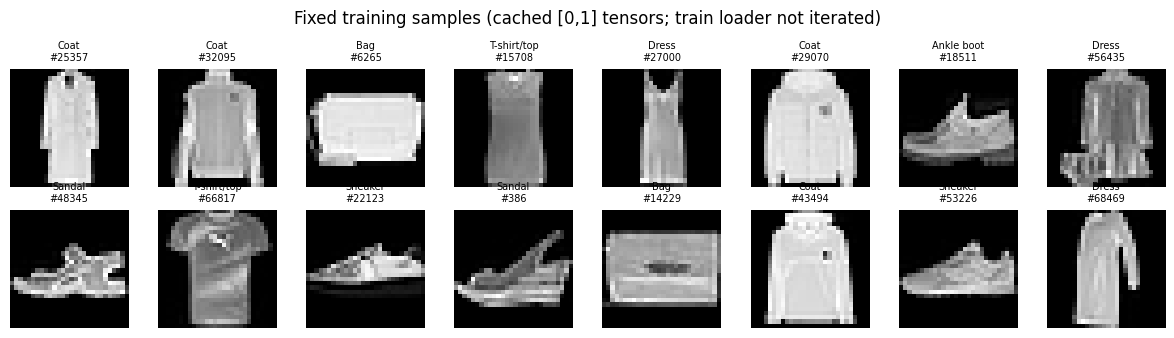

Training loader shuffle generator untouched before training: state length 5056


In [7]:
pooled_dataset = TensorDataset(ALL_IMAGES, ALL_LABELS)
train_set = Subset(pooled_dataset, train_idx.tolist())
val_set = Subset(pooled_dataset, val_idx.tolist())
test_set = Subset(pooled_dataset, test_idx.tolist())

train_loader_generator = torch.Generator().manual_seed(DATALOADER_SHUFFLE_SEED)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=train_loader_generator,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
assert len(train_set) == 56000 and len(val_set) == 7000 and len(test_set) == 7000
NUM_TRAIN_BATCHES = len(train_loader)
print("Batches per epoch (train / val / test):", NUM_TRAIN_BATCHES, len(val_loader), len(test_loader))

inspect_idx = train_idx[:16]
inspect_images = ALL_IMAGES[inspect_idx]
assert inspect_images.shape == (16, *IMAGE_SHAPE) and inspect_images.dtype == torch.float32
assert float(inspect_images.min()) >= 0.0 and float(inspect_images.max()) <= 1.0
gan_view = inspect_images * 2 - 1
assert float(gan_view.min()) >= -1.0 and float(gan_view.max()) <= 1.0

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, idx in zip(axes.flat, inspect_images, inspect_idx):
    ax.imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{CLASS_NAMES[labels[idx]]}\n#{idx}", fontsize=7)
    ax.axis("off")
fig.suptitle("Fixed training samples (cached [0,1] tensors; train loader not iterated)")
plt.tight_layout()
plt.show()
plt.close(fig)
print("Training loader shuffle generator untouched before training: state length",
      train_loader_generator.get_state().numel())

In [8]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, IMAGE_NUMEL),
            nn.Tanh(),
            nn.Unflatten(1, IMAGE_SHAPE),
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(IMAGE_NUMEL, 512),
            nn.LeakyReLU(LEAKY_SLOPE),
            nn.Linear(512, 256),
            nn.LeakyReLU(LEAKY_SLOPE),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)


def init_linear_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=INIT_STD)
        nn.init.zeros_(module.bias)


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def layer_signature(model):
    sig = []
    for m in model.net:
        if isinstance(m, nn.Linear):
            sig.append(f"Linear({m.in_features},{m.out_features})")
        elif isinstance(m, nn.LeakyReLU):
            sig.append(f"LeakyReLU({m.negative_slope})")
        elif isinstance(m, nn.Unflatten):
            sig.append("Unflatten(" + ",".join(str(s) for s in m.unflattened_size) + ")")
        elif isinstance(m, (nn.ReLU, nn.Tanh, nn.Sigmoid, nn.Flatten)):
            sig.append(type(m).__name__)
        else:
            sig.append(f"UNEXPECTED:{type(m).__name__}")
    return sig


EXPECTED_G_SIGNATURE = ["Linear(100,256)", "ReLU", "Linear(256,512)", "ReLU", "Linear(512,784)", "Tanh",
                        "Unflatten(1,28,28)"]
EXPECTED_D_SIGNATURE = ["Flatten", "Linear(784,512)", "LeakyReLU(0.2)", "Linear(512,256)", "LeakyReLU(0.2)",
                        "Linear(256,1)", "Sigmoid"]
ALLOWED_MODULE_TYPES = (Generator, Discriminator, nn.Sequential, nn.Linear, nn.ReLU, nn.LeakyReLU,
                        nn.Tanh, nn.Sigmoid, nn.Flatten, nn.Unflatten)


@torch.no_grad()
def check_models(G_model, D_model, seed=SANITY_CHECK_SEED):
    """Architecture, parameter-count and output shape/range checks. Returns dict of booleans."""
    checks = {
        "generator_signature": layer_signature(G_model) == EXPECTED_G_SIGNATURE,
        "discriminator_signature": layer_signature(D_model) == EXPECTED_D_SIGNATURE,
        "only_allowed_layer_types": all(isinstance(m, ALLOWED_MODULE_TYPES)
                                        for model in (G_model, D_model) for m in model.modules()),
        "generator_param_count": sum(p.numel() for p in G_model.parameters()) == EXPECTED_G_PARAMS,
        "discriminator_param_count": sum(p.numel() for p in D_model.parameters()) == EXPECTED_D_PARAMS,
    }
    device = next(G_model.parameters()).device
    was_training = (G_model.training, D_model.training)
    G_model.eval(); D_model.eval()
    z = seeded_normal(16, LATENT_DIM, seed).to(device)
    fake = G_model(z)
    d_fake = D_model(fake)
    real = (ALL_IMAGES[train_idx[:16]] * 2 - 1).to(device)
    d_real = D_model(real)
    checks["generator_output_shape"] = tuple(fake.shape) == (16, *IMAGE_SHAPE)
    checks["generator_output_range"] = bool(fake.min() >= -1.0 and fake.max() <= 1.0)
    checks["discriminator_output_shape"] = tuple(d_fake.shape) == (16, 1) and tuple(d_real.shape) == (16, 1)
    checks["discriminator_output_range"] = bool(d_fake.min() >= 0 and d_fake.max() <= 1
                                                and d_real.min() >= 0 and d_real.max() <= 1)
    G_model.train(was_training[0]); D_model.train(was_training[1])
    return checks


torch.manual_seed(SEED)
G = Generator().to(DEVICE)
G.apply(init_linear_weights)
D = Discriminator().to(DEVICE)
D.apply(init_linear_weights)

G_PARAMS, D_PARAMS = count_trainable(G), count_trainable(D)
assert G_PARAMS == EXPECTED_G_PARAMS, f"Generator params {G_PARAMS} != {EXPECTED_G_PARAMS}"
assert D_PARAMS == EXPECTED_D_PARAMS, f"Discriminator params {D_PARAMS} != {EXPECTED_D_PARAMS}"

for name, model in (("G", G), ("D", D)):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            assert torch.count_nonzero(m.bias) == 0, f"{name}: non-zero bias after init"
            w = m.weight.detach()
            w_std = float(w.std())
            assert abs(w_std - INIT_STD) < 0.002, f"{name}: weight std {w_std:.4f} not ~0.02"
            assert abs(float(w.mean())) < 0.002, f"{name}: weight mean not ~0"

model_checks = check_models(G, D)
for k, v in model_checks.items():
    assert v, f"Model check failed: {k}"

ARCHITECTURE_METADATA = {
    "generator_layers": EXPECTED_G_SIGNATURE,
    "discriminator_layers": EXPECTED_D_SIGNATURE,
    "generator_trainable_parameters": G_PARAMS,
    "discriminator_trainable_parameters": D_PARAMS,
    "latent_dim": LATENT_DIM,
    "latent_prior": "N(0, I)",
    "generator_output": "Tanh, [B,1,28,28] in [-1,1]",
    "discriminator_output": "Sigmoid probability, [B,1] in [0,1]",
    "weight_init": "Linear weights N(0, 0.02^2), biases 0",
}
print(G)
print(D)
print(f"Trainable parameters: G = {G_PARAMS:,}  D = {D_PARAMS:,}")
print("All model checks passed:", model_checks)

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
    (6): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)
Discriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Linear(in_features=256, out_features=1, bias=True)
    (6): Sigmoid()
  )
)
Trainable parameters: G = 559,632  D = 533,505
All model checks passed: {'generator_signature': True, 'discriminator_signature': True, 'only_allowed_layer_types': True, 'generator_param_count': True, 'discriminator_param_count': True, 'generator_output_shape': True, 'generator_output_range': True, 'discrim

In [9]:
FID_BLOCK_INDEX = InceptionV3.BLOCK_INDEX_BY_DIM[FID_FEATURE_DIM]
inception_model = InceptionV3([FID_BLOCK_INDEX], resize_input=True, normalize_input=True,
                              requires_grad=False, use_fid_inception=True).to(DEVICE).eval()


@torch.no_grad()
def extract_inception_features(images01):
    if images01.ndim != 4 or tuple(images01.shape[1:]) != IMAGE_SHAPE:
        raise ValueError(f"Expected [N,1,28,28], got {tuple(images01.shape)}")
    lo, hi = float(images01.min()), float(images01.max())
    if lo < 0.0 or hi > 1.0:
        raise ValueError(f"FID inputs must be in [0,1], got [{lo}, {hi}]")
    feats = []
    for start in range(0, images01.shape[0], FID_BATCH_SIZE):
        batch = images01[start:start + FID_BATCH_SIZE].to(DEVICE, dtype=torch.float32)
        batch_rgb = batch.repeat(1, 3, 1, 1)
        pool3 = inception_model(batch_rgb)[0]
        if pool3.shape[2:] != (1, 1):
            pool3 = F.adaptive_avg_pool2d(pool3, output_size=(1, 1))
        feats.append(pool3.squeeze(3).squeeze(2).to(torch.float64).cpu())
    feats = torch.cat(feats).numpy()
    if feats.shape != (images01.shape[0], FID_FEATURE_DIM) or not np.isfinite(feats).all():
        raise RuntimeError(f"Bad Inception features: shape {feats.shape}")
    return feats


def feature_statistics(feats):
    feats = np.asarray(feats, dtype=np.float64)
    mu = np.mean(feats, axis=0, dtype=np.float64)
    sigma = np.cov(feats, rowvar=False).astype(np.float64)
    return mu, sigma


def fid_from_features(mu_real, sigma_real, fake_feats):
    mu_fake, sigma_fake = feature_statistics(fake_feats)
    fid = float(calculate_frechet_distance(mu_real, sigma_real, mu_fake, sigma_fake))
    if not math.isfinite(fid):
        raise FloatingPointError(f"Non-finite FID: {fid}")
    return fid


@torch.no_grad()
def generate_images01(generator, z, batch_size=GEN_BATCH_SIZE):
    generator.eval()
    out = []
    for start in range(0, z.shape[0], batch_size):
        x = generator(z[start:start + batch_size].to(DEVICE))
        out.append(((x + 1.0) / 2.0).clamp_(0.0, 1.0).cpu())
    return torch.cat(out)


def collect_from_loader(loader, max_items=None):
    imgs, labs = [], []
    count = 0
    for x, y in loader:
        imgs.append(x)
        labs.append(y)
        count += x.shape[0]
        if max_items is not None and count >= max_items:
            break
    imgs, labs = torch.cat(imgs), torch.cat(labs)
    if max_items is not None:
        imgs, labs = imgs[:max_items], labs[:max_items]
    return imgs, labs

VAL_FID_Z = seeded_normal(VAL_FID_NUM_FAKE, LATENT_DIM, VAL_FID_NOISE_SEED)

cuda_sync(); t0 = time.perf_counter()
val_real_images, val_real_labels = collect_from_loader(val_loader, VAL_FID_NUM_REAL)
assert val_real_images.shape == (VAL_FID_NUM_REAL, *IMAGE_SHAPE)
assert torch.equal(
    val_real_images,
    ALL_IMAGES[val_idx[:VAL_FID_NUM_REAL]]
), "Validation real images do not match the expected validation split."
VAL_REAL_FEATS = extract_inception_features(val_real_images)
MU_VAL_REAL, SIGMA_VAL_REAL = feature_statistics(VAL_REAL_FEATS)
cuda_sync()
VAL_REAL_FEATURE_TIME = time.perf_counter() - t0
assert VAL_REAL_FEATS.shape == (VAL_FID_NUM_REAL, FID_FEATURE_DIM)
assert MU_VAL_REAL.dtype == np.float64 and SIGMA_VAL_REAL.shape == (FID_FEATURE_DIM, FID_FEATURE_DIM)
print(f"Validation real features: {VAL_REAL_FEATS.shape} in {VAL_REAL_FEATURE_TIME:.1f}s; "
      f"class counts {np.bincount(val_real_labels.numpy(), minlength=NUM_CLASSES).tolist()}")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 207MB/s]


Validation real features: (3000, 2048) in 13.7s; class counts [280, 326, 308, 270, 293, 311, 290, 312, 289, 321]


In [10]:
bce_loss = nn.BCELoss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR_G, betas=ADAM_BETAS, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)
opt_D = torch.optim.Adam(D.parameters(), lr=LR_D, betas=ADAM_BETAS, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)

TRAIN_NOISE_GENERATOR = torch.Generator(device="cpu").manual_seed(TRAIN_NOISE_SEED)
MONITOR_Z = seeded_normal(NUM_MONITOR_SAMPLES, LATENT_DIM, MONITOR_NOISE_SEED)

def set_requires_grad(module, flag):
    for p in module.parameters():
        p.requires_grad_(flag)


@torch.no_grad()
def pixel_diversity_metrics(images01):
    flat = images01.reshape(images01.shape[0], -1).to(torch.float64).cpu()
    pixel_std = float(flat.std(dim=0, correction=0).mean())
    dists = torch.cdist(flat, flat, p=1) / flat.shape[1]
    iu = torch.triu_indices(flat.shape[0], flat.shape[0], offset=1)
    pairwise_l1 = float(dists[iu[0], iu[1]].mean())
    return pixel_std, pairwise_l1


CSV_FIELDS = ["epoch", "generator_loss", "discriminator_loss", "d_real_mean", "d_fake_mean", "val_fid",
              "fixed_noise_pixel_std", "fixed_noise_mean_pairwise_l1", "train_time_sec",
              "val_fid_eval_time_sec", "epoch_wall_time_sec", "best_checkpoint_saved",
              "num_train_samples", "num_train_batches"]


def csv_value(v):
    return "" if v is None else v


def append_history_row(row, path=HISTORY_CSV_PATH):
    with open(path, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=CSV_FIELDS).writerow({k: csv_value(row.get(k)) for k in CSV_FIELDS})


def build_checkpoint(epoch, val_fid, include_history=False):
    ckpt = {
        "generator_state_dict": G.state_dict(),
        "discriminator_state_dict": D.state_dict(),
        "optimizer_G_state_dict": opt_G.state_dict(),
        "optimizer_D_state_dict": opt_D.state_dict(),
        "epoch": int(epoch),
        "val_fid_at_epoch": val_fid,
        "best_epoch": BEST_EPOCH,
        "best_val_fid": BEST_VAL_FID,
        "model_id": MODEL_ID,
        "model_name": MODEL_NAME,
        "architecture": to_jsonable(ARCHITECTURE_METADATA),
        "config": to_jsonable(EXPERIMENT_CONFIG),
        "split_sha256": dict(SPLIT_HASHES),
        "torch_version": str(torch.__version__),
    }
    if include_history:
        ckpt["history"] = to_jsonable(HISTORY)
        ckpt["train_noise_generator_state"] = TRAIN_NOISE_GENERATOR.get_state()
        ckpt["train_loader_generator_state"] = train_loader_generator.get_state()
    return ckpt


HISTORY = []
PROGRESSION_SNAPSHOTS = {}
BEST_VAL_FID, BEST_EPOCH = None, None
with open(HISTORY_CSV_PATH, "w", newline="") as f:
    csv.DictWriter(f, fieldnames=CSV_FIELDS).writeheader()

cuda_sync()
TRAINING_LOOP_START = time.perf_counter()
for epoch in tqdm(range(1, NUM_EPOCHS + 1), desc="Epochs"):
    cuda_sync()
    epoch_start = time.perf_counter()
    G.train(); D.train()
    sum_g = torch.zeros((), dtype=torch.float64, device=DEVICE)
    sum_d = torch.zeros_like(sum_g); sum_real = torch.zeros_like(sum_g); sum_fake = torch.zeros_like(sum_g)
    n_seen, n_batches = 0, 0

    for real01, _ in train_loader:
        real = real01.to(DEVICE, non_blocking=True) * 2.0 - 1.0
        b = real.shape[0]
        z = torch.randn(b, LATENT_DIM, generator=TRAIN_NOISE_GENERATOR).to(DEVICE, non_blocking=True)
        real_targets = torch.full((b, 1), REAL_LABEL, device=DEVICE)
        fake_targets = torch.full((b, 1), FAKE_LABEL, device=DEVICE)

        opt_D.zero_grad(set_to_none=True)
        fake = G(z)
        d_real = D(real)
        d_fake = D(fake.detach())
        loss_D = 0.5 * (bce_loss(d_real, real_targets) + bce_loss(d_fake, fake_targets))
        loss_D.backward()
        opt_D.step()

        set_requires_grad(D, False)
        opt_G.zero_grad(set_to_none=True)
        loss_G = bce_loss(D(fake), real_targets)
        loss_G.backward()
        opt_G.step()
        set_requires_grad(D, True)

        sum_d += loss_D.detach().double() * b
        sum_g += loss_G.detach().double() * b
        sum_real += d_real.detach().double().sum()
        sum_fake += d_fake.detach().double().sum()
        n_seen += b
        n_batches += 1

    cuda_sync()
    train_time = time.perf_counter() - epoch_start
    assert n_seen == EXPECTED_TOTALS["train"] and n_batches == NUM_TRAIN_BATCHES
    epoch_g, epoch_d = float(sum_g) / n_seen, float(sum_d) / n_seen
    epoch_real, epoch_fake = float(sum_real) / n_seen, float(sum_fake) / n_seen
    if not all(math.isfinite(v) for v in (epoch_g, epoch_d, epoch_real, epoch_fake)):
        raise FloatingPointError(f"Non-finite training statistics at epoch {epoch}")

    monitor_images = generate_images01(G, MONITOR_Z)
    pixel_std, pairwise_l1 = pixel_diversity_metrics(monitor_images)
    if epoch in PROGRESSION_EPOCHS:
        PROGRESSION_SNAPSHOTS[epoch] = monitor_images[:NUM_PROGRESSION_SHOWN].clone()

    val_fid, val_time, saved_best = None, None, False
    if epoch in VAL_FID_EPOCHS:
        cuda_sync(); t_val = time.perf_counter()
        fake_val = generate_images01(G, VAL_FID_Z)
        assert fake_val.shape == (VAL_FID_NUM_FAKE, *IMAGE_SHAPE)
        fake_val_feats = extract_inception_features(fake_val)
        assert fake_val_feats.shape == (VAL_FID_NUM_FAKE, FID_FEATURE_DIM)
        val_fid = fid_from_features(MU_VAL_REAL, SIGMA_VAL_REAL, fake_val_feats)
        cuda_sync(); val_time = time.perf_counter() - t_val
        if BEST_VAL_FID is None or val_fid < BEST_VAL_FID:
            BEST_VAL_FID, BEST_EPOCH = val_fid, epoch
            save_torch_atomic(build_checkpoint(epoch, val_fid), BEST_MODEL_PATH)
            saved_best = True

    cuda_sync()
    row = {
        "epoch": epoch, "generator_loss": epoch_g, "discriminator_loss": epoch_d,
        "d_real_mean": epoch_real, "d_fake_mean": epoch_fake, "val_fid": val_fid,
        "fixed_noise_pixel_std": pixel_std, "fixed_noise_mean_pairwise_l1": pairwise_l1,
        "train_time_sec": train_time, "val_fid_eval_time_sec": val_time,
        "epoch_wall_time_sec": time.perf_counter() - epoch_start,
        "best_checkpoint_saved": saved_best, "num_train_samples": n_seen, "num_train_batches": n_batches,
    }
    HISTORY.append(row)
    save_torch_atomic(build_checkpoint(epoch, val_fid, include_history=True), LAST_CKPT_PATH)
    append_history_row(row)

    fid_txt = f" | val FID {val_fid:.3f}{' *best*' if saved_best else ''}" if val_fid is not None else ""
    print(f"Epoch {epoch:02d} | G {epoch_g:.4f} | D {epoch_d:.4f} | D(real) {epoch_real:.3f} | "
          f"D(fake) {epoch_fake:.3f} | pix-std {pixel_std:.4f} | pair-L1 {pairwise_l1:.4f} | "
          f"train {train_time:.1f}s | wall {row['epoch_wall_time_sec']:.1f}s{fid_txt}")

cuda_sync()
TRAINING_LOOP_WALL_TIME = time.perf_counter() - TRAINING_LOOP_START
assert len(HISTORY) == NUM_EPOCHS and [r["epoch"] for r in HISTORY] == list(range(1, NUM_EPOCHS + 1))
assert sorted(PROGRESSION_SNAPSHOTS) == PROGRESSION_EPOCHS
assert BEST_EPOCH in VAL_FID_EPOCHS and BEST_MODEL_PATH.is_file() and LAST_CKPT_PATH.is_file()
print(f"Training finished in {TRAINING_LOOP_WALL_TIME / 60:.1f} min. "
      f"Best validation FID {BEST_VAL_FID:.4f} at epoch {BEST_EPOCH}.")

Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | G 2.5119 | D 0.2188 | D(real) 0.952 | D(fake) 0.267 | pix-std 0.0346 | pair-L1 0.0383 | train 5.1s | wall 5.1s
Epoch 02 | G 4.1924 | D 0.1799 | D(real) 0.912 | D(fake) 0.120 | pix-std 0.0754 | pair-L1 0.0870 | train 3.4s | wall 3.4s
Epoch 03 | G 3.1803 | D 0.2735 | D(real) 0.843 | D(fake) 0.178 | pix-std 0.1612 | pair-L1 0.1795 | train 3.4s | wall 3.4s
Epoch 04 | G 2.9297 | D 0.3185 | D(real) 0.804 | D(fake) 0.211 | pix-std 0.1758 | pair-L1 0.1919 | train 3.8s | wall 3.8s
Epoch 05 | G 2.5172 | D 0.3318 | D(real) 0.787 | D(fake) 0.222 | pix-std 0.1851 | pair-L1 0.1992 | train 4.2s | wall 32.2s | val FID 260.591 *best*
Epoch 06 | G 2.5540 | D 0.3477 | D(real) 0.782 | D(fake) 0.229 | pix-std 0.2004 | pair-L1 0.2101 | train 3.5s | wall 3.5s
Epoch 07 | G 2.3662 | D 0.3564 | D(real) 0.774 | D(fake) 0.234 | pix-std 0.2100 | pair-L1 0.2199 | train 3.5s | wall 3.5s
Epoch 08 | G 2.2907 | D 0.3824 | D(real) 0.757 | D(fake) 0.252 | pix-std 0.2316 | pair-L1 0.2439 | train 4.1s | wall 4.1

In [11]:
best_ckpt = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=True)
G_best = Generator().to(DEVICE)
G_best.load_state_dict(best_ckpt["generator_state_dict"])
D_best = Discriminator().to(DEVICE)
D_best.load_state_dict(best_ckpt["discriminator_state_dict"])
G_best.eval(); D_best.eval()
for p in list(G_best.parameters()) + list(D_best.parameters()):
    p.requires_grad_(False)
assert best_ckpt["epoch"] == BEST_EPOCH and math.isclose(best_ckpt["best_val_fid"], BEST_VAL_FID)

best_model_checks = check_models(G_best, D_best)
assert all(best_model_checks.values()), best_model_checks

recomputed_feats = extract_inception_features(generate_images01(G_best, VAL_FID_Z))
BEST_VAL_FID_RECOMPUTED = fid_from_features(MU_VAL_REAL, SIGMA_VAL_REAL, recomputed_feats)
assert math.isclose(BEST_VAL_FID_RECOMPUTED, BEST_VAL_FID, rel_tol=1e-3, abs_tol=1e-3), \
    f"Recomputed best val FID {BEST_VAL_FID_RECOMPUTED} != recorded {BEST_VAL_FID}"
print(f"Loaded best checkpoint (epoch {BEST_EPOCH}); val FID recorded {BEST_VAL_FID:.4f}, "
      f"recomputed {BEST_VAL_FID_RECOMPUTED:.4f}")

Loaded best checkpoint (epoch 30); val FID recorded 150.6114, recomputed 150.6114


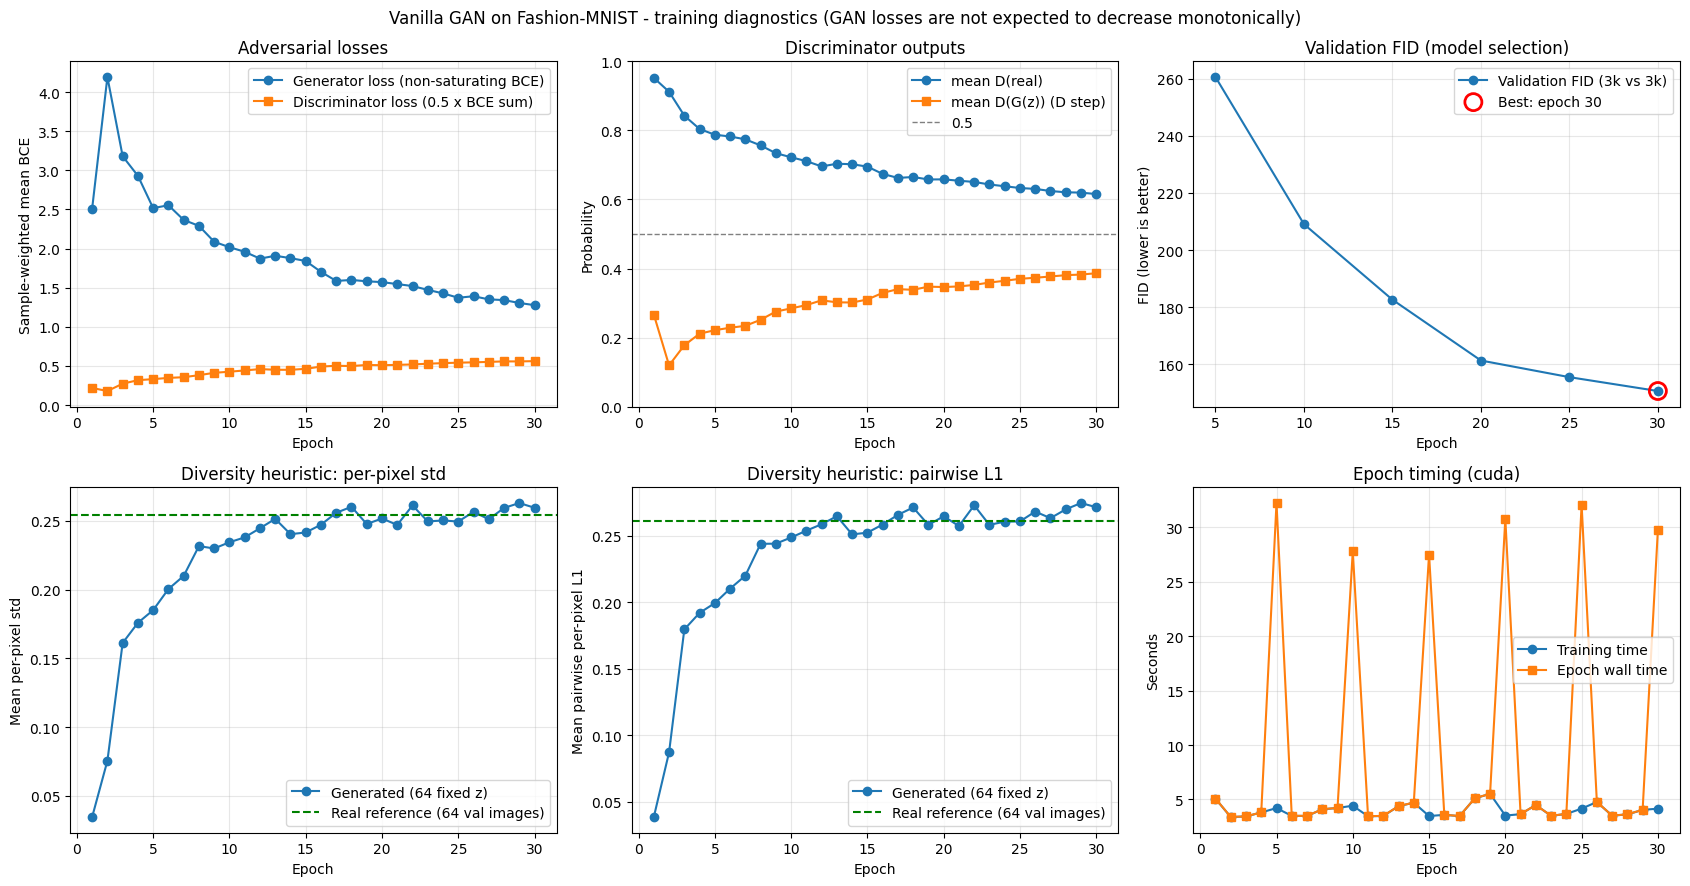

Saved figure: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/figures/training_curves.png


In [12]:
epochs = np.array([r["epoch"] for r in HISTORY])
hist = {k: np.array([np.nan if r[k] is None else r[k] for r in HISTORY], dtype=float)
        for k in ["generator_loss", "discriminator_loss", "d_real_mean", "d_fake_mean", "val_fid",
                  "fixed_noise_pixel_std", "fixed_noise_mean_pairwise_l1", "train_time_sec", "epoch_wall_time_sec"]}

REAL_REFERENCE_PIXEL_STD, REAL_REFERENCE_PAIRWISE_L1 = pixel_diversity_metrics(ALL_IMAGES[val_idx[:NUM_MONITOR_SAMPLES]])

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
ax = axes[0, 0]
ax.plot(epochs, hist["generator_loss"], "o-", label="Generator loss (non-saturating BCE)")
ax.plot(epochs, hist["discriminator_loss"], "s-", label="Discriminator loss (0.5 x BCE sum)")
ax.set(xlabel="Epoch", ylabel="Sample-weighted mean BCE", title="Adversarial losses")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.plot(epochs, hist["d_real_mean"], "o-", label="mean D(real)")
ax.plot(epochs, hist["d_fake_mean"], "s-", label="mean D(G(z)) (D step)")
ax.axhline(0.5, color="gray", ls="--", lw=1, label="0.5")
ax.set(xlabel="Epoch", ylabel="Probability", title="Discriminator outputs", ylim=(0, 1))
ax.legend(); ax.grid(alpha=0.3)

ax = axes[0, 2]
mask = ~np.isnan(hist["val_fid"])
ax.plot(epochs[mask], hist["val_fid"][mask], "o-", label="Validation FID (3k vs 3k)")
ax.scatter([BEST_EPOCH], [BEST_VAL_FID], s=150, facecolors="none", edgecolors="red", lw=2,
           label=f"Best: epoch {BEST_EPOCH}", zorder=5)
ax.set(xlabel="Epoch", ylabel="FID (lower is better)", title="Validation FID (model selection)")
ax.set_xticks(VAL_FID_EPOCHS); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1, 0]
ax.plot(epochs, hist["fixed_noise_pixel_std"], "o-", label="Generated (64 fixed z)")
ax.axhline(REAL_REFERENCE_PIXEL_STD, color="green", ls="--", label="Real reference (64 val images)")
ax.set(xlabel="Epoch", ylabel="Mean per-pixel std", title="Diversity heuristic: per-pixel std")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1, 1]
ax.plot(epochs, hist["fixed_noise_mean_pairwise_l1"], "o-", label="Generated (64 fixed z)")
ax.axhline(REAL_REFERENCE_PAIRWISE_L1, color="green", ls="--", label="Real reference (64 val images)")
ax.set(xlabel="Epoch", ylabel="Mean pairwise per-pixel L1", title="Diversity heuristic: pairwise L1")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1, 2]
ax.plot(epochs, hist["train_time_sec"], "o-", label="Training time")
ax.plot(epochs, hist["epoch_wall_time_sec"], "s-", label="Epoch wall time")
ax.set(xlabel="Epoch", ylabel="Seconds", title=f"Epoch timing ({DEVICE.type})")
ax.legend(); ax.grid(alpha=0.3)

fig.suptitle("Vanilla GAN on Fashion-MNIST - training diagnostics (GAN losses are not expected to decrease monotonically)")
plt.tight_layout()
save_figure(fig, FIG_PATHS["training_curves"])

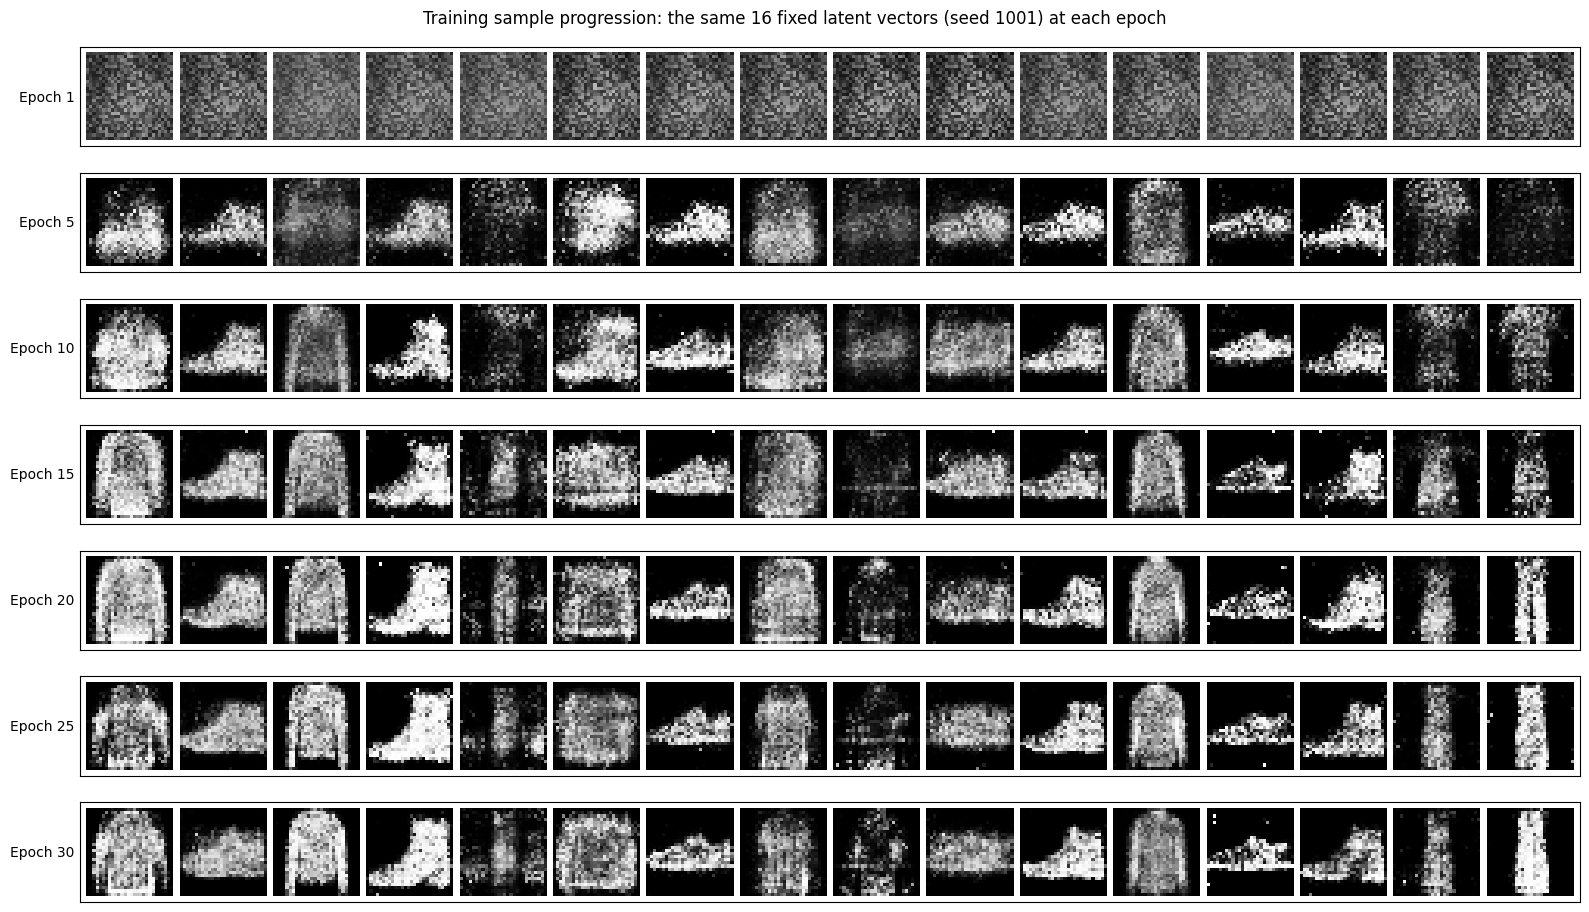

Saved figure: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/figures/training_sample_progression.png


In [13]:
fig, axes = plt.subplots(len(PROGRESSION_EPOCHS), 1, figsize=(16, 1.25 * len(PROGRESSION_EPOCHS) + 0.6))
for ax, ep in zip(axes, PROGRESSION_EPOCHS):
    grid = make_grid(PROGRESSION_SNAPSHOTS[ep], nrow=NUM_PROGRESSION_SHOWN, padding=2, pad_value=1.0)
    ax.imshow(grid[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_ylabel(f"Epoch {ep}", rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle(f"Training sample progression: the same {NUM_PROGRESSION_SHOWN} fixed latent vectors "
             f"(seed {MONITOR_NOISE_SEED}) at each epoch")
plt.tight_layout()
save_figure(fig, FIG_PATHS["training_sample_progression"])

In [14]:
def series_summary(values):
    v = np.asarray(values, dtype=float)
    return {"first": v[0], "last": v[-1], "min": v.min(), "max": v.max(), "mean": v.mean(),
            "std_across_epochs": v.std(), "epoch_of_min": int(epochs[v.argmin()]),
            "epoch_of_max": int(epochs[v.argmax()]),
            "num_epoch_to_epoch_increases": int(np.sum(np.diff(v) > 0))}


VAL_FID_BY_EPOCH = {int(r["epoch"]): r["val_fid"] for r in HISTORY if r["val_fid"] is not None}
evidence = {
    "generator_loss": series_summary(hist["generator_loss"]),
    "discriminator_loss": series_summary(hist["discriminator_loss"]),
    "d_real_mean": series_summary(hist["d_real_mean"]),
    "d_fake_mean": series_summary(hist["d_fake_mean"]),
    "d_real_minus_d_fake_last_epoch": hist["d_real_mean"][-1] - hist["d_fake_mean"][-1],
    "fixed_noise_pixel_std": series_summary(hist["fixed_noise_pixel_std"]),
    "fixed_noise_mean_pairwise_l1": series_summary(hist["fixed_noise_mean_pairwise_l1"]),
    "real_reference": {"pixel_std": REAL_REFERENCE_PIXEL_STD, "mean_pairwise_l1": REAL_REFERENCE_PAIRWISE_L1,
                       "source": "first 64 images of the final validation split"},
    "val_fid_by_epoch": VAL_FID_BY_EPOCH,
}

flags = []
ps, pl = evidence["fixed_noise_pixel_std"], evidence["fixed_noise_mean_pairwise_l1"]
if ps["last"] < 0.5 * ps["max"] or pl["last"] < 0.5 * pl["max"]:
    flags.append("Fixed-noise diversity at epoch 30 is below half of its maximum over training "
                 "(possible diversity loss; inspect the progression figure).")
if pl["last"] < 0.5 * REAL_REFERENCE_PAIRWISE_L1:
    flags.append("Final generated pairwise L1 is below half of the real-image reference "
                 "(generated batch is much less varied than real data in pixel space).")
if hist["d_real_mean"][-1] > 0.9 and hist["d_fake_mean"][-1] < 0.1:
    flags.append("At epoch 30 the discriminator separates real and fake strongly (D(real)>0.9, D(fake)<0.1).")
if evidence["generator_loss"]["num_epoch_to_epoch_increases"] >= NUM_EPOCHS // 3:
    flags.append(f"Generator loss increased between consecutive epochs "
                 f"{evidence['generator_loss']['num_epoch_to_epoch_increases']} times (oscillating adversarial dynamics).")
last_val = VAL_FID_BY_EPOCH[VAL_FID_EPOCHS[-1]]
if BEST_EPOCH != VAL_FID_EPOCHS[-1]:
    flags.append(f"Validation FID at epoch {VAL_FID_EPOCHS[-1]} ({last_val:.3f}) is worse than at best epoch "
                 f"{BEST_EPOCH} ({BEST_VAL_FID:.3f}); later training did not improve FID.")
if not flags:
    flags.append("No heuristic flag triggered. This does not prove the absence of mode collapse.")
evidence["heuristic_flags"] = flags
evidence["flag_thresholds"] = {
    "diversity_drop": "last < 0.5 * max over training (either indicator)",
    "vs_real_reference": "generated pairwise L1 < 0.5 * real reference",
    "discriminator_dominance": "D(real) > 0.9 and D(fake) < 0.1 at final epoch",
    "loss_oscillation": f">= {NUM_EPOCHS // 3} epoch-to-epoch increases of generator loss",
    "late_fid_degradation": "best epoch is not the final validation epoch",
}
INSTABILITY_EVIDENCE = evidence

print(json.dumps(to_jsonable({k: evidence[k] for k in
      ["d_real_minus_d_fake_last_epoch", "real_reference", "val_fid_by_epoch"]}), indent=2))
for name in ["generator_loss", "discriminator_loss", "d_real_mean", "d_fake_mean",
             "fixed_noise_pixel_std", "fixed_noise_mean_pairwise_l1"]:
    s = evidence[name]
    print(f"{name:30s} first {s['first']:.4f} last {s['last']:.4f} min {s['min']:.4f} (ep {s['epoch_of_min']}) "
          f"max {s['max']:.4f} (ep {s['epoch_of_max']}) increases {s['num_epoch_to_epoch_increases']}")
print("\nHeuristic flags:")
for f_ in flags:
    print(" -", f_)

{
  "d_real_minus_d_fake_last_epoch": 0.22927789508651142,
  "real_reference": {
    "pixel_std": 0.25428718138098255,
    "mean_pairwise_l1": 0.26116477523325793,
    "source": "first 64 images of the final validation split"
  },
  "val_fid_by_epoch": {
    "5": 260.5909182838159,
    "10": 209.05657641655932,
    "15": 182.59820117950656,
    "20": 161.298871627234,
    "25": 155.47036742464678,
    "30": 150.61139675656608
  }
}
generator_loss                 first 2.5119 last 1.2773 min 1.2773 (ep 30) max 4.1924 (ep 2) increases 5
discriminator_loss             first 0.2188 last 0.5618 min 0.1799 (ep 2) max 0.5618 (ep 30) increases 23
d_real_mean                    first 0.9522 last 0.6157 min 0.6157 (ep 30) max 0.9522 (ep 1) increases 3
d_fake_mean                    first 0.2670 last 0.3864 min 0.1197 (ep 2) max 0.3864 (ep 30) increases 24
fixed_noise_pixel_std          first 0.0346 last 0.2595 min 0.0346 (ep 1) max 0.2630 (ep 29) increases 21
fixed_noise_mean_pairwise_l1   first

In [15]:
cuda_sync(); t0 = time.perf_counter()
test_real_images, test_real_labels = collect_from_loader(test_loader)
assert test_real_images.shape == (TEST_FID_NUM_REAL, *IMAGE_SHAPE), test_real_images.shape
assert torch.equal(test_real_labels, ALL_LABELS[test_idx]), "Test loader order/labels mismatch"
assert np.all(np.bincount(test_real_labels.numpy(), minlength=NUM_CLASSES) == TEST_PER_CLASS)
assert np.intersect1d(test_idx, train_idx).size == 0, "Test FID must not use training images"

TEST_FID_Z = seeded_normal(TEST_FID_NUM_FAKE, LATENT_DIM, TEST_FID_NOISE_SEED)
test_fake_images = generate_images01(G_best, TEST_FID_Z)
assert test_fake_images.shape == (TEST_FID_NUM_FAKE, *IMAGE_SHAPE)

TEST_REAL_FEATS = extract_inception_features(test_real_images)
TEST_FAKE_FEATS = extract_inception_features(test_fake_images)
assert TEST_REAL_FEATS.shape == (TEST_FID_NUM_REAL, FID_FEATURE_DIM)
assert TEST_FAKE_FEATS.shape == (TEST_FID_NUM_FAKE, FID_FEATURE_DIM)
MU_TEST_REAL, SIGMA_TEST_REAL = feature_statistics(TEST_REAL_FEATS)
FINAL_TEST_FID = fid_from_features(MU_TEST_REAL, SIGMA_TEST_REAL, TEST_FAKE_FEATS)
cuda_sync()
TEST_FID_EVAL_TIME = time.perf_counter() - t0

FINAL_TEST_FID_RESULT = {
    "fid": FINAL_TEST_FID,
    "num_real_test_images": int(TEST_REAL_FEATS.shape[0]),
    "num_generated_images": int(TEST_FAKE_FEATS.shape[0]),
    "feature_dim": int(TEST_REAL_FEATS.shape[1]),
    "real_feature_shape": list(TEST_REAL_FEATS.shape),
    "generated_feature_shape": list(TEST_FAKE_FEATS.shape),
    "real_source": "held-out stratified test split (all 7000 images, 700 per class)",
    "generated_noise_seed": TEST_FID_NOISE_SEED,
    "checkpoint": "best_model.pth",
    "checkpoint_epoch": BEST_EPOCH,
    "eval_time_sec": TEST_FID_EVAL_TIME,
}
print(f"Final test FID (best epoch {BEST_EPOCH}; 7000 real test vs 7000 generated): {FINAL_TEST_FID:.4f} "
      f"[{TEST_FID_EVAL_TIME:.1f}s]")

Final test FID (best epoch 30; 7000 real test vs 7000 generated): 149.3074 [69.5s]


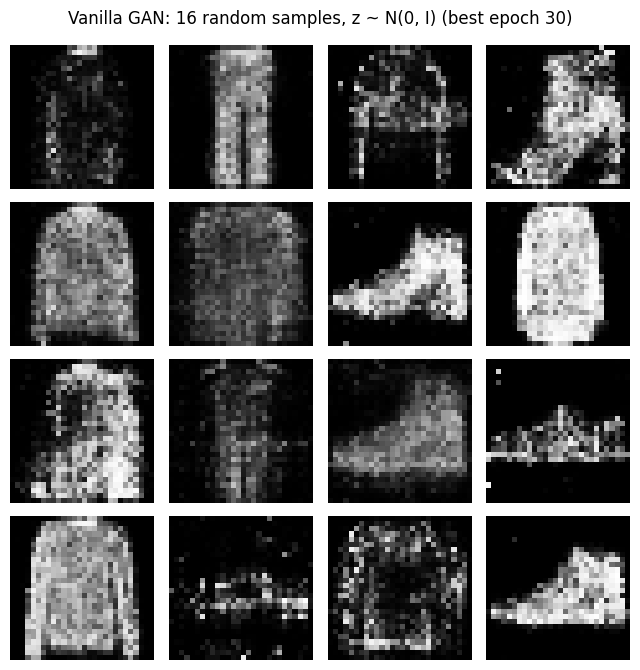

Saved figure: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/figures/random_samples_4x4.png


In [16]:
RANDOM_Z = seeded_normal(NUM_RANDOM_SAMPLES, LATENT_DIM, RANDOM_SAMPLES_SEED)
random_samples = generate_images01(G_best, RANDOM_Z)
assert random_samples.shape == (16, *IMAGE_SHAPE)

fig, axes = plt.subplots(4, 4, figsize=(6.5, 6.8))
for ax, img in zip(axes.flat, random_samples):
    ax.imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(f"Vanilla GAN: 16 random samples, z ~ N(0, I) (best epoch {BEST_EPOCH})")
plt.tight_layout()
save_figure(fig, FIG_PATHS["random_samples_4x4"])

In [17]:
def invert_image(generator, target01, seed):
    """Approximate latent inversion of a frozen generator. target01: [1,1,28,28] in [0,1] on DEVICE."""
    generator.eval()
    assert not any(p.requires_grad for p in generator.parameters()), "Generator must be frozen"
    gen = torch.Generator(device="cpu").manual_seed(seed)
    restarts = []
    best = None
    for r in range(INVERSION_RESTARTS):
        z0 = torch.randn(1, LATENT_DIM, generator=gen).to(DEVICE)
        z = z0.clone().requires_grad_(True)
        opt = torch.optim.Adam([z], lr=INVERSION_LR)
        for _ in range(INVERSION_STEPS):
            opt.zero_grad(set_to_none=True)
            recon = (generator(z) + 1.0) / 2.0
            objective = F.mse_loss(recon, target01) + INVERSION_Z_PRIOR_WEIGHT * z.pow(2).mean()
            objective.backward()
            opt.step()
        with torch.no_grad():
            recon = (generator(z) + 1.0) / 2.0
            mse = float(F.mse_loss(recon, target01))
            obj = mse + INVERSION_Z_PRIOR_WEIGHT * float(z.pow(2).mean())
        if not (math.isfinite(mse) and math.isfinite(obj)):
            raise FloatingPointError("Non-finite inversion objective")
        info = {"restart": r, "final_mse": mse, "final_objective": obj,
                "initial_z_norm": float(z0.norm()), "final_z_norm": float(z.detach().norm())}
        restarts.append(info)
        if best is None or obj < best[0]["final_objective"]:
            best = (info, z.detach().clone(), recon.detach().clone())
    info, z_best, recon_best = best
    return {"z": z_best, "reconstruction01": recon_best, "selected_restart": info["restart"],
            "final_mse": info["final_mse"], "final_objective": info["final_objective"],
            "latent_norm": info["final_z_norm"], "restarts": restarts}


test_labels_np = labels[test_idx]
ENDPOINTS = {}
for key, class_id in (("class_A", INTERP_CLASS_A), ("class_B", INTERP_CLASS_B)):
    pos = int(np.flatnonzero(test_labels_np == class_id)[0])
    pooled = int(test_idx[pos])
    assert int(labels[pooled]) == class_id
    target = ALL_IMAGES[pooled].unsqueeze(0).to(DEVICE)
    t0 = time.perf_counter()
    res = invert_image(G_best, target, INVERSION_SEEDS[key])
    res.update({"class_id": class_id, "class_name": CLASS_NAMES[class_id], "test_split_position": pos,
                "pooled_index": pooled, "target01": target.cpu(), "seed": INVERSION_SEEDS[key],
                "inversion_time_sec": time.perf_counter() - t0})
    ENDPOINTS[key] = res
    print(f"{CLASS_NAMES[class_id]:12s} test pos {pos:4d} pooled idx {pooled:5d} | restart {res['selected_restart']} "
          f"| MSE {res['final_mse']:.5f} | objective {res['final_objective']:.5f} | ||z|| {res['latent_norm']:.3f}")

z_a, z_b = ENDPOINTS["class_A"]["z"], ENDPOINTS["class_B"]["z"]
Z_INTERP = torch.cat([(1.0 - a) * z_a + a * z_b for a in INTERP_ALPHAS], dim=0)
assert Z_INTERP.shape == (len(INTERP_ALPHAS), LATENT_DIM)
interp_images = generate_images01(G_best, Z_INTERP.cpu())
assert torch.allclose(interp_images[0], ENDPOINTS["class_A"]["reconstruction01"][0].cpu(), atol=1e-5)
assert torch.allclose(interp_images[-1], ENDPOINTS["class_B"]["reconstruction01"][0].cpu(), atol=1e-5)

T-shirt/top  test pos    0 pooled idx 39323 | restart 0 | MSE 0.01618 | objective 0.01630 | ||z|| 10.847
Trouser      test pos    3 pooled idx  6906 | restart 1 | MSE 0.02804 | objective 0.02814 | ||z|| 9.682


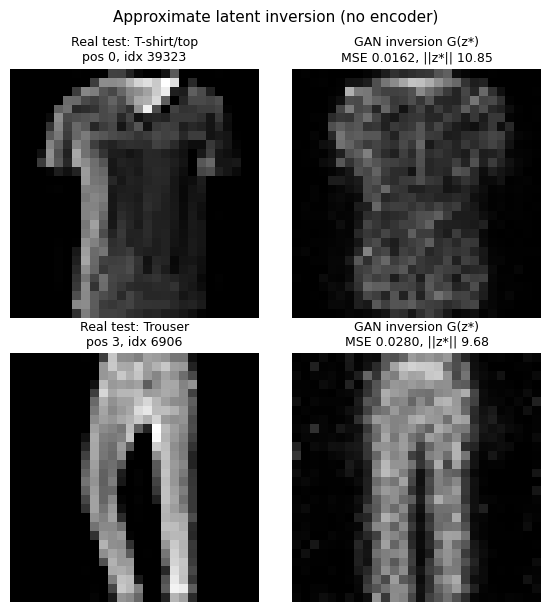

Saved figure: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/figures/latent_inversion_endpoints.png


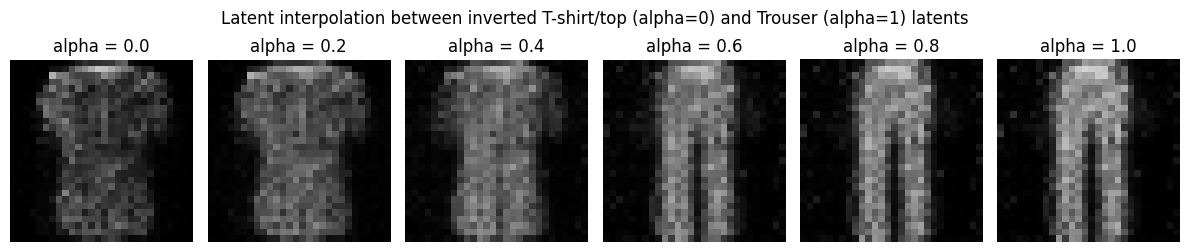

Saved figure: /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/figures/latent_interpolation.png


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(5.8, 6.2))
for row, key in enumerate(("class_A", "class_B")):
    e = ENDPOINTS[key]
    axes[row, 0].imshow(e["target01"][0, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Real test: {e['class_name']}\npos {e['test_split_position']}, idx {e['pooled_index']}",
                           fontsize=9)
    axes[row, 1].imshow(e["reconstruction01"][0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"GAN inversion G(z*)\nMSE {e['final_mse']:.4f}, ||z*|| {e['latent_norm']:.2f}", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
fig.suptitle("Approximate latent inversion (no encoder)", fontsize=11)
plt.tight_layout()
save_figure(fig, FIG_PATHS["latent_inversion_endpoints"])

fig, axes = plt.subplots(1, len(INTERP_ALPHAS), figsize=(2.0 * len(INTERP_ALPHAS), 2.6))
for ax, img, a in zip(axes, interp_images, INTERP_ALPHAS):
    ax.imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"alpha = {a:.1f}")
    ax.axis("off")
fig.suptitle("Latent interpolation between inverted T-shirt/top (alpha=0) and Trouser (alpha=1) latents")
plt.tight_layout()
save_figure(fig, FIG_PATHS["latent_interpolation"])

LATENT_INTERPOLATION_RESULT = {
    "method": "linear interpolation between latent-inversion endpoints of the frozen best generator",
    "note": "Vanilla GAN has no encoder; endpoints are approximate optimisation results, not encodings.",
    "alphas": INTERP_ALPHAS,
    "interpolated_latent_norms": [float(z.norm()) for z in Z_INTERP],
    "inversion": {
        "objective": "MSE((G(z)+1)/2, target) + 1e-4 * mean(z^2)",
        "optimizer": "Adam", "learning_rate": INVERSION_LR, "steps_per_restart": INVERSION_STEPS,
        "restart_count": INVERSION_RESTARTS, "z_prior_weight": INVERSION_Z_PRIOR_WEIGHT,
        "restart_selection": "lowest final objective", "generator_checkpoint_epoch": BEST_EPOCH,
    },
    "endpoints": {
        key: {k: e[k] for k in ["class_id", "class_name", "test_split_position", "pooled_index", "seed",
                                "selected_restart", "final_mse", "final_objective", "latent_norm",
                                "restarts", "inversion_time_sec"]}
        for key, e in ENDPOINTS.items()
    },
}

In [19]:
LATENCY_Z = seeded_normal(LATENCY_BATCH_SIZE, LATENT_DIM, LATENCY_NOISE_SEED).to(DEVICE)
G_best.eval()
latency_ms = []
with torch.no_grad():
    for _ in range(LATENCY_WARMUP_RUNS):
        cuda_sync()
        _ = G_best(LATENCY_Z)
        cuda_sync()
    for _ in range(LATENCY_TIMED_RUNS):
        cuda_sync()
        t0 = time.perf_counter()
        out = G_best(LATENCY_Z)
        cuda_sync()
        latency_ms.append((time.perf_counter() - t0) * 1000.0)
assert out.shape == (LATENCY_BATCH_SIZE, *IMAGE_SHAPE)
assert len(latency_ms) == LATENCY_TIMED_RUNS
lat = np.array(latency_ms)
LATENCY_RESULT = {
    "definition": "Generator forward pass only (no FID/Inception), torch.no_grad(), CUDA synchronised per run",
    "batch_size": LATENCY_BATCH_SIZE,
    "warmup_runs": LATENCY_WARMUP_RUNS,
    "timed_runs": LATENCY_TIMED_RUNS,
    "mean_ms_per_batch": float(lat.mean()),
    "std_ms_per_batch": float(lat.std(ddof=1)),
    "median_ms_per_batch": float(np.median(lat)),
    "min_ms_per_batch": float(lat.min()),
    "max_ms_per_batch": float(lat.max()),
    "mean_ms_per_image": float(lat.mean() / LATENCY_BATCH_SIZE),
    "device": str(DEVICE),
    "hardware": HARDWARE,
    "note": "Latency is hardware-dependent.",
}
print(json.dumps({k: v for k, v in LATENCY_RESULT.items() if k != "hardware"}, indent=2))

{
  "definition": "Generator forward pass only (no FID/Inception), torch.no_grad(), CUDA synchronised per run",
  "batch_size": 64,
  "warmup_runs": 20,
  "timed_runs": 100,
  "mean_ms_per_batch": 0.38279846999671463,
  "std_ms_per_batch": 0.17570729165435203,
  "median_ms_per_batch": 0.36631300002909484,
  "min_ms_per_batch": 0.1992460000792562,
  "max_ms_per_batch": 1.4364470000600704,
  "mean_ms_per_image": 0.005981226093698666,
  "device": "cuda",
  "note": "Latency is hardware-dependent."
}


In [20]:
TRAIN_TIMES = [r["train_time_sec"] for r in HISTORY]
WALL_TIMES = [r["epoch_wall_time_sec"] for r in HISTORY]

FINAL_CSV_FIELDS = CSV_FIELDS + ["is_selected_best_epoch"]
with open(HISTORY_CSV_PATH, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=FINAL_CSV_FIELDS)
    writer.writeheader()
    for r in HISTORY:
        out_row = {k: csv_value(r.get(k)) for k in CSV_FIELDS}
        out_row["is_selected_best_epoch"] = r["epoch"] == BEST_EPOCH
        writer.writerow(out_row)

ARTIFACTS = {
    "project_dir": PROJECT_DIR,
    "best_model": BEST_MODEL_PATH, "last_checkpoint": LAST_CKPT_PATH, "metrics": METRICS_PATH,
    "training_history_csv": HISTORY_CSV_PATH, "experiment_config": CONFIG_PATH, "split_report": SPLIT_REPORT_PATH,
    **{f"figure_{k}": v for k, v in FIG_PATHS.items()},
    "dataset_cache": DATA_DIR,
}

METRICS = {
    "model": {
        "model_id": MODEL_ID, "model_name": MODEL_NAME, "notebook": NOTEBOOK_NAME,
        "architecture": ARCHITECTURE_METADATA,
        "parameter_counts": {"generator": G_PARAMS, "discriminator": D_PARAMS, "total": G_PARAMS + D_PARAMS},
        "latent_dim": LATENT_DIM,
    },
    "hyperparameters": EXPERIMENT_CONFIG["hyperparameters"],
    "dataset_split": {
        "seed": SEED, "totals": SPLIT_REPORT["totals"], "per_class_counts": SPLIT_PER_CLASS,
        "sha256": SPLIT_HASHES, "split_report": SPLIT_REPORT_PATH,
    },
    "model_selection": {
        "criterion": "lowest validation FID among scheduled epochs",
        "val_fid_epochs": VAL_FID_EPOCHS, "val_fid_by_epoch": VAL_FID_BY_EPOCH,
        "num_real_validation_images": VAL_FID_NUM_REAL, "num_generated_images": VAL_FID_NUM_FAKE,
        "real_validation_feature_shape": list(VAL_REAL_FEATS.shape),
        "best_epoch": BEST_EPOCH, "best_val_fid": BEST_VAL_FID,
        "best_val_fid_recomputed_from_checkpoint": BEST_VAL_FID_RECOMPUTED,
        "note": "Validation FID is used only for checkpoint selection, not as the final reported score.",
    },
    "final_test_fid": FINAL_TEST_FID_RESULT,
    "fid_protocol": {
        **EXPERIMENT_CONFIG["fid"],
        "limitations": "InceptionV3 is ImageNet-pretrained; Fashion-MNIST images are grayscale (channel-replicated) "
                       "and upsampled from 28x28 to 299x299, so FID is a relative comparison metric under this "
                       "shared protocol, not an absolute quality measure. No domain-specific FID is used.",
    },
    "reconstruction_metrics": {
        "mse": None, "psnr": None, "ssim": None, "status": "N/A",
        "reason": "Unconditional Vanilla GAN has no paired reconstruction path; MSE/PSNR/SSIM are not applicable.",
    },
    "training": {
        "num_epochs_completed": len(HISTORY),
        "num_train_samples_per_epoch": EXPECTED_TOTALS["train"],
        "num_train_batches_per_epoch": NUM_TRAIN_BATCHES,
        "per_epoch": HISTORY,
        "total_training_time_sec": float(np.sum(TRAIN_TIMES)),
        "mean_epoch_training_time_sec": float(np.mean(TRAIN_TIMES)),
        "total_epoch_wall_time_sec": float(np.sum(WALL_TIMES)),
        "mean_epoch_wall_time_sec": float(np.mean(WALL_TIMES)),
        "training_loop_wall_time_sec": TRAINING_LOOP_WALL_TIME,
        "validation_real_feature_precompute_time_sec": VAL_REAL_FEATURE_TIME,
        "epoch_wall_time_definition": EXPERIMENT_CONFIG["monitoring"]["epoch_wall_time_definition"],
        "loss_interpretation": "Adversarial losses oscillate and are not expected to decrease monotonically.",
    },
    "mode_collapse_heuristics": {
        "indicators": EXPERIMENT_CONFIG["monitoring"]["diversity_indicators"],
        "fixed_noise_count": NUM_MONITOR_SAMPLES, "fixed_noise_seed": MONITOR_NOISE_SEED,
        "per_epoch_pixel_std": [r["fixed_noise_pixel_std"] for r in HISTORY],
        "per_epoch_mean_pairwise_l1": [r["fixed_noise_mean_pairwise_l1"] for r in HISTORY],
        "evidence_summary": INSTABILITY_EVIDENCE,
        "caveats": [
            "Pixel-space diversity on 64 fixed samples is a heuristic indicator only.",
            "These indicators do not prove or fully measure mode coverage or mode collapse.",
            "High pixel variance can come from noise or artefacts rather than semantic diversity.",
        ],
    },
    "inference_latency": LATENCY_RESULT,
    "latent_interpolation": LATENT_INTERPOLATION_RESULT,
    "runtime": {"versions": RUNTIME_VERSIONS, "device": str(DEVICE), "hardware": HARDWARE},
    "artifacts": ARTIFACTS,
}

for name, value in [("best_val_fid", BEST_VAL_FID), ("final_test_fid", FINAL_TEST_FID),
                    ("latency_mean", LATENCY_RESULT["mean_ms_per_batch"])]:
    assert value is not None and math.isfinite(value), f"{name} is not finite"

write_json_strict(METRICS, METRICS_PATH)
write_json_strict(EXPERIMENT_CONFIG, CONFIG_PATH)
write_json_strict(SPLIT_REPORT, SPLIT_REPORT_PATH)

print("Artifacts:")
for k, v in ARTIFACTS.items():
    p = Path(v)
    size = p.stat().st_size if p.is_file() else None
    print(f"  {k:40s} {p}" + (f"  ({size:,} bytes)" if size is not None else ""))

Artifacts:
  project_dir                              /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan
  best_model                               /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/best_model.pth  (13,141,645 bytes)
  last_checkpoint                          /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/last_checkpoint.pth  (13,157,805 bytes)
  metrics                                  /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/metrics.json  (37,650 bytes)
  training_history_csv                     /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/training_history.csv  (5,857 bytes)
  experiment_config                        /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/experiment_config.json  (7,246 bytes)
  split_report                             /content/drive/MyDrive/generative-model-comparison/03_vanilla_gan/results/

In [21]:
CHECKS = []


def check(name, condition, detail=""):
    CHECKS.append((name, bool(condition), detail))


def all_finite_numbers(obj):
    if isinstance(obj, bool) or obj is None or isinstance(obj, str):
        return True
    if isinstance(obj, (int, float)):
        return math.isfinite(obj)
    if isinstance(obj, dict):
        return all(all_finite_numbers(v) for v in obj.values())
    if isinstance(obj, list):
        return all(all_finite_numbers(v) for v in obj)
    return False


missing = [str(p) for p in REQUIRED_OUTPUTS if not (Path(p).is_file() and Path(p).stat().st_size > 0)]
check("All required output files exist and are non-empty", not missing, f"missing/empty: {missing}")

strict_ok, strict_err = True, ""
try:
    m = load_json_strict(METRICS_PATH)
    cfg = load_json_strict(CONFIG_PATH)
    sr = load_json_strict(SPLIT_REPORT_PATH)
except Exception as exc:
    strict_ok, strict_err = False, repr(exc)
    m, cfg, sr = {}, {}, {}
check("Strict JSON (no NaN/Infinity) for metrics/config/split report", strict_ok, strict_err)

recomputed = make_stratified_split(labels, SEED)
re_checks = verify_split(dict(zip(["train", "validation", "test"], recomputed)), labels)
check("Split totals/per-class exact, no overlap/duplicates, all 70,000 indices covered",
      all(re_checks.values()) and all(split_checks.values()),
      str({k: v for k, v in re_checks.items() if not v}))
recomputed_hashes = {n: sha256_int64(a) for n, a in zip(["train", "validation", "test"], recomputed)}
check("Split hashes: recomputed == split_report == metrics",
      recomputed_hashes == sr.get("sha256") == m.get("dataset_split", {}).get("sha256") == SPLIT_HASHES)
expected_pc = {"train": TRAIN_PER_CLASS, "validation": VAL_PER_CLASS, "test": TEST_PER_CLASS}
saved_pc = sr.get("per_class_counts", {})
check("Split report totals and per-class counts",
      sr.get("totals") == EXPECTED_TOTALS
      and all(len(saved_pc.get(s, {})) == NUM_CLASSES
              and all(v == expected_pc[s] for v in saved_pc[s].values()) for s in expected_pc))

ckpt_best = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=True)
ckpt_last = torch.load(LAST_CKPT_PATH, map_location=DEVICE, weights_only=True)
G_chk, D_chk = Generator().to(DEVICE), Discriminator().to(DEVICE)
G_chk.load_state_dict(ckpt_best["generator_state_dict"]); D_chk.load_state_dict(ckpt_best["discriminator_state_dict"])
arch_checks = check_models(G_chk, D_chk)
check("Generator/Discriminator architectures, parameter counts and output ranges correct",
      all(arch_checks.values()) and count_trainable(G_chk) == EXPECTED_G_PARAMS
      and count_trainable(D_chk) == EXPECTED_D_PARAMS
      and m.get("model", {}).get("parameter_counts", {}).get("generator") == EXPECTED_G_PARAMS
      and m.get("model", {}).get("parameter_counts", {}).get("discriminator") == EXPECTED_D_PARAMS,
      str(arch_checks))

with open(HISTORY_CSV_PATH, newline="") as f:
    csv_rows = list(csv.DictReader(f))
required_cols = set(FINAL_CSV_FIELDS)
check("Exactly 30 training epochs recorded (CSV and metrics) with all required columns",
      len(csv_rows) == NUM_EPOCHS and [int(r["epoch"]) for r in csv_rows] == list(range(1, NUM_EPOCHS + 1))
      and required_cols.issubset(csv_rows[0].keys())
      and m.get("training", {}).get("num_epochs_completed") == NUM_EPOCHS
      and len(m.get("training", {}).get("per_epoch", [])) == NUM_EPOCHS)

csv_fids = {int(r["epoch"]): float(r["val_fid"]) for r in csv_rows if r["val_fid"] != ""}
best_from_csv = min(csv_fids, key=lambda e: (csv_fids[e], e)) if csv_fids else None
check("Validation FID present exactly on epochs 5,10,...,30", sorted(csv_fids) == VAL_FID_EPOCHS)
check("Best epoch is the lowest recorded validation FID",
      best_from_csv == BEST_EPOCH == m.get("model_selection", {}).get("best_epoch")
      and math.isclose(csv_fids.get(BEST_EPOCH, float("nan")), m["model_selection"]["best_val_fid"], rel_tol=1e-9)
      and [r["is_selected_best_epoch"] == "True" for r in csv_rows].count(True) == 1,
      f"csv best {best_from_csv}, metrics best {m.get('model_selection', {}).get('best_epoch')}")

check("Checkpoint metadata agrees with metrics/configuration",
      ckpt_best["epoch"] == m["model_selection"]["best_epoch"]
      and math.isclose(ckpt_best["best_val_fid"], m["model_selection"]["best_val_fid"], rel_tol=1e-9)
      and ckpt_best["config"]["hyperparameters"] == cfg.get("hyperparameters")
      and ckpt_best["config"]["architecture"] == cfg.get("architecture")
      and ckpt_best["architecture"]["generator_trainable_parameters"] == EXPECTED_G_PARAMS
      and ckpt_best["architecture"]["discriminator_trainable_parameters"] == EXPECTED_D_PARAMS
      and ckpt_best["split_sha256"] == SPLIT_HASHES
      and all(k in ckpt_best for k in ["optimizer_G_state_dict", "optimizer_D_state_dict"])
      and ckpt_last["epoch"] == NUM_EPOCHS and len(ckpt_last.get("history", [])) == NUM_EPOCHS)

tf = m.get("final_test_fid", {})
check("Final FID: 7,000 real test vs 7,000 generated, 2048-D features, finite",
      tf.get("num_real_test_images") == 7000 and tf.get("num_generated_images") == 7000
      and tf.get("feature_dim") == 2048 and tf.get("real_feature_shape") == [7000, 2048]
      and tf.get("generated_feature_shape") == [7000, 2048]
      and isinstance(tf.get("fid"), float) and math.isfinite(tf["fid"])
      and m.get("fid_protocol", {}).get("feature_dim") == 2048)

rm = m.get("reconstruction_metrics", {})
check("MSE/PSNR/SSIM explicitly N/A (null), not zero",
      all(k in rm and rm[k] is None for k in ("mse", "psnr", "ssim")) and rm.get("status") == "N/A")

lm = m.get("inference_latency", {})
check("Latency: batch 64, 20 warm-ups, 100 timed runs",
      lm.get("batch_size") == 64 and lm.get("warmup_runs") == 20 and lm.get("timed_runs") == 100
      and all(math.isfinite(lm.get(k, float("nan"))) for k in
              ["mean_ms_per_batch", "std_ms_per_batch", "median_ms_per_batch", "mean_ms_per_image"]))

li = m.get("latent_interpolation", {})
eps_ = li.get("endpoints", {})
check("Latent interpolation: six required alphas and both inversion endpoints recorded",
      li.get("alphas") == [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
      and set(eps_) == {"class_A", "class_B"}
      and eps_["class_A"]["class_id"] == 0 and eps_["class_B"]["class_id"] == 1
      and all(len(eps_[k]["restarts"]) == INVERSION_RESTARTS for k in eps_)
      and all(math.isfinite(eps_[k][f]) for k in eps_ for f in ("final_mse", "final_objective", "latent_norm"))
      and li.get("inversion", {}).get("steps_per_restart") == INVERSION_STEPS
      and li.get("inversion", {}).get("restart_count") == INVERSION_RESTARTS)

per_epoch_ok = all(all(math.isfinite(r[k]) for k in ["generator_loss", "discriminator_loss", "d_real_mean",
                                                    "d_fake_mean", "fixed_noise_pixel_std",
                                                    "fixed_noise_mean_pairwise_l1", "train_time_sec",
                                                    "epoch_wall_time_sec"])
                   and ((r["val_fid"] is None) != (r["epoch"] in VAL_FID_EPOCHS))
                   for r in m.get("training", {}).get("per_epoch", []))
check("All applicable metrics finite; strict JSON contains no NaN/Infinity",
      strict_ok and per_epoch_ok and all_finite_numbers(m) and all_finite_numbers(cfg) and all_finite_numbers(sr))

width = max(len(c[0]) for c in CHECKS)
for name, ok, detail in CHECKS:
    print(f"[{'PASS' if ok else 'FAIL'}] {name:{width}s}" + (f"  -> {detail}" if (not ok and detail) else ""))
failed = [c[0] for c in CHECKS if not c[1]]
if failed:
    raise RuntimeError(f"{len(failed)} verification check(s) FAILED: {failed}")
print(f"\nAll {len(CHECKS)} verification checks PASSED.")
print(f"Best validation FID {m['model_selection']['best_val_fid']:.4f} (epoch {m['model_selection']['best_epoch']}); "
      f"final test FID {tf['fid']:.4f}; generator latency {lm['mean_ms_per_batch']:.3f} ms / 64 images on {lm['device']}.")

[PASS] All required output files exist and are non-empty                                
[PASS] Strict JSON (no NaN/Infinity) for metrics/config/split report                    
[PASS] Split totals/per-class exact, no overlap/duplicates, all 70,000 indices covered  
[PASS] Split hashes: recomputed == split_report == metrics                              
[PASS] Split report totals and per-class counts                                         
[PASS] Generator/Discriminator architectures, parameter counts and output ranges correct
[PASS] Exactly 30 training epochs recorded (CSV and metrics) with all required columns  
[PASS] Validation FID present exactly on epochs 5,10,...,30                             
[PASS] Best epoch is the lowest recorded validation FID                                 
[PASS] Checkpoint metadata agrees with metrics/configuration                            
[PASS] Final FID: 7,000 real test vs 7,000 generated, 2048-D features, finite           
[PASS] MSE/PSNR/SSIM 